## Understanding KryptoNet-40

The pretrained model from the paper, and what LoRA would cost on it. The plotting code is in `include/plots_kryptonet.py`; every figure is also saved to `figures/`.

In [1]:
from include.models import load_kryptonet
from include.figures import use_paper_style, savefig
from include import plots_kryptonet as plots

use_paper_style()
model = load_kryptonet()
print(model)
print(sum(p.numel() for p in model.parameters()), "parameters")

Sequential(
  (0): Linear(in_features=40, out_features=512, bias=True)
  (1): ReLU()
  (2): Linear(in_features=512, out_features=512, bias=True)
  (3): ReLU()
  (4): Linear(in_features=512, out_features=512, bias=True)
  (5): ReLU()
  (6): Linear(in_features=512, out_features=512, bias=True)
  (7): ReLU()
  (8): Linear(in_features=512, out_features=1, bias=True)
)
809473 parameters


### 1. Zero-shot accuracy
The pretrained model used as it is, with Chebyshev 95% intervals.

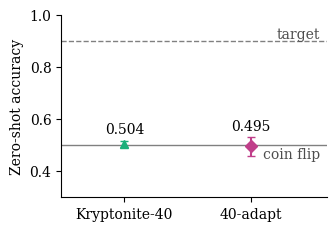

In [2]:
fig = plots.plot_zero_shot()
savefig(fig, "kn_zero_shot")

Its logits, split by the true label.

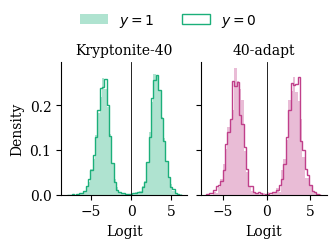

In [3]:
fig = plots.plot_logits()
savefig(fig, "kn_logits")

### 2. What the first layer looks at
Size of the first-layer weights coming out of each input feature. Coloured bars are the features in the strongest pair of Kryptonite-40 and of 40-adapt.

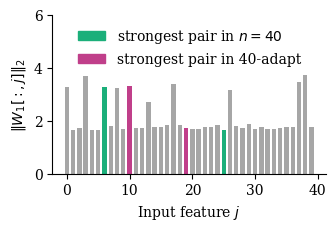

In [4]:
fig = plots.plot_input_weights()
savefig(fig, "kn_input_weights")

### 3. Weight matrices and LoRA
Singular values of the four hidden weight matrices, and how much of each matrix its top $r$ directions hold.

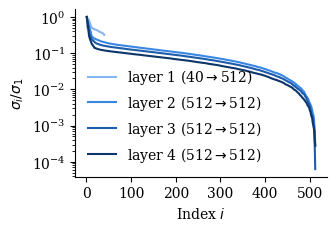

In [5]:
fig = plots.plot_weight_spectra()
savefig(fig, "kn_weight_spectra")

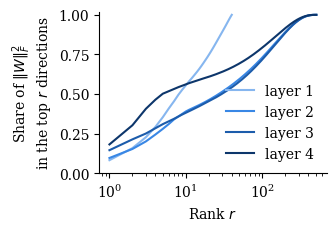

In [6]:
fig = plots.plot_weight_energy()
savefig(fig, "kn_weight_energy")

Trainable parameters for LoRA at rank $r$ on every layer, against full fine-tuning and the two probes from the paper.

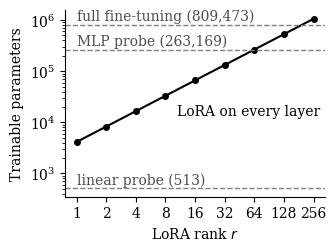

In [7]:
fig = plots.plot_lora_params()
savefig(fig, "kn_lora_params")